In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

from config import BOOKS_PATH, INTERACTIONS_PATH, REVIEWS_PATH, AUTHORS_PATH

In [2]:
import pandas as pd

### Goodreads Books

In [4]:
df_books = pd.read_json(BOOKS_PATH, lines=True)

print(df_books.columns.tolist())

['isbn', 'text_reviews_count', 'series', 'country_code', 'language_code', 'popular_shelves', 'asin', 'is_ebook', 'average_rating', 'kindle_asin', 'similar_books', 'description', 'format', 'link', 'authors', 'publisher', 'num_pages', 'publication_day', 'isbn13', 'publication_month', 'edition_information', 'publication_year', 'url', 'image_url', 'book_id', 'ratings_count', 'work_id', 'title', 'title_without_series']


In [5]:
df_authors = pd.read_json(AUTHORS_PATH, lines=True)
author_names = df_authors.set_index(df_authors["author_id"].astype(str))["name"].to_dict()

df_books["authors"] = df_books["authors"].apply(
    lambda authors: [author_names.get(str(a["author_id"]), a["author_id"]) for a in authors]
)

df_books[["isbn", "title", "authors", "num_pages", "description", "similar_books"]].head()

,isbn,title,authors,num_pages,description,similar_books
0,,Vision of Sir Launfal and Other Poems,[James Russell Lowell],80,Number 30 in a series of literary pamphlets pu...,[]
1,0811223981,Fairy Tales: Dramolettes,"[Robert Walser, Daniele Pantano, James Reidel,...",128,Fairy Tales gathers the unconventional verse d...,[]
2,0374428115,Growltiger's Last Stand and Other Poems,"[T.S. Eliot, Errol Le Cain]",,Three poems describe the nighttime adventures ...,[]
3,0156182890,The Cocktail Party,[T.S. Eliot],190,A modern verse play about the search for meani...,"[1230072, 315167, 676169, 18522, 124335, 88263..."
4,1942004192,Louder Than Everything You Love,[Nicole Rollender],118,Louder Than Everything You Love is about trans...,"[25869488, 23630890, 25448131, 25464039, 42166..."


In [6]:
df_books["average_rating"] = pd.to_numeric(df_books["average_rating"])
df_books["average_rating"].describe()

count    36514.000000
mean         4.063838
std          0.399965
min          0.000000
25%          3.840000
50%          4.100000
75%          4.310000
max          5.000000
Name: average_rating, dtype: float64

### Goodreads Interactions

In [7]:
df_interactions = pd.read_json(INTERACTIONS_PATH, lines=True)

print(df_interactions.columns.tolist())

['user_id', 'book_id', 'review_id', 'is_read', 'rating', 'review_text_incomplete', 'date_added', 'date_updated', 'read_at', 'started_at']


In [8]:
# Obs: rating de 0 representa não atribuição de rating, já que não existe a opção de colocar rating 0.

display(df_interactions["is_read"].value_counts())
display(df_interactions["rating"].value_counts().sort_index())

is_read
False    1420740
True     1313610
Name: count, dtype: int64

rating
0    1505291
1      20497
2      64084
3     237942
4     405565
5     500971
Name: count, dtype: int64

### Qualidade dos livros

In [16]:
def is_empty(s):
    return s.isna() | (s.astype(str).str.strip() == "")


STAT_LABELS = {
    "count": "quantidade",
    "mean": "média",
    "std": "desvio padrão",
    "min": "mínimo",
    "max": "máximo",
}


def summarize(s, name, percentiles=(0.05, 0.1, 0.25, 0.5, 0.75, 0.95)):
    out = s.describe(percentiles=list(percentiles))
    out.index = [STAT_LABELS.get(i, i) for i in out.index]
    return out.apply("{:,.1f}".format).to_frame(name)


fields = {
    "description": "Sinopse",
    "isbn": "ISBN",
    "isbn13": "ISBN13",
    "language_code": "Idioma",
    "num_pages": "Número de páginas",
    "publication_year": "Ano de publicação",
}
empty_fields = pd.DataFrame(
    {
        "Livros sem o campo": [is_empty(df_books[c]).sum() for c in fields],
        "% dos livros": [round(is_empty(df_books[c]).mean() * 100, 1) for c in fields],
    },
    index=list(fields.values()),
)
print(f"Campos vazios, em {len(df_books):,} livros")
display(empty_fields)

isbn13 = df_books.loc[~is_empty(df_books["isbn13"]), "isbn13"]
print(f"\nLivros com book_id repetido: {df_books['book_id'].duplicated().sum()}")
print(f"Livros com ISBN13 preenchido: {len(isbn13):,}")
print(f"ISBN13 repetido entre livros: {isbn13.duplicated().sum()}")

df_books["desc_words"] = df_books["description"].fillna("").str.split().str.len()
words_with_desc = df_books.loc[df_books["desc_words"] > 0, "desc_words"]
print(f"\nTamanho das sinopses, só livros com sinopse ({len(words_with_desc):,} livros)")
display(summarize(words_with_desc, "palavras na sinopse"))

language = df_books["language_code"].fillna("").replace("", "(vazio)").value_counts().head(10)
print("\nIdiomas mais frequentes")
display(language.rename_axis("idioma").to_frame("livros"))

df_books["ratings_count"] = pd.to_numeric(df_books["ratings_count"])
print(f"\nLivros com average_rating = 0: {(df_books['average_rating'] == 0).sum()}")
print("\nNúmero de avaliações por livro (ratings_count)")
display(summarize(df_books["ratings_count"], "avaliações por livro", percentiles=(0.25, 0.5, 0.75, 0.9, 0.99)))

Campos vazios, em 36,514 livros


,Livros sem o campo,% dos livros
Sinopse,7526,20.6
ISBN,9980,27.3
ISBN13,8155,22.3
Idioma,19462,53.3
Número de páginas,7505,20.6
Ano de publicação,5816,15.9



Livros com book_id repetido: 0
Livros com ISBN13 preenchido: 28,359
ISBN13 repetido entre livros: 0

Tamanho das sinopses, só livros com sinopse (28,988 livros)


,palavras na sinopse
quantidade,"28,988.0"
média,115.3
desvio padrão,97.8
mínimo,1.0
5%,14.0
10%,25.0
25%,53.0
50%,98.0
75%,152.0
95%,271.0



Idiomas mais frequentes


,livros
idioma,
(vazio),19462
eng,8393
ara,1608
per,924
en-US,868
spa,837
por,462
ita,455
tur,369



Livros com average_rating = 0: 11

Número de avaliações por livro (ratings_count)


,avaliações por livro
quantidade,"36,514.0"
média,279.7
desvio padrão,"7,633.4"
mínimo,0.0
25%,9.0
50%,23.0
75%,69.0
90%,223.0
99%,"2,744.6"
máximo,"1,029,527.0"


### Estrutura das interações

In [17]:
n_rows = len(df_interactions)
n_users = df_interactions["user_id"].nunique()
n_books = df_interactions["book_id"].nunique()

print(f"Interações: {n_rows:,}")
print(f"Usuários únicos: {n_users:,}")
print(f"Livros únicos: {n_books:,}")
print(f"Densidade da matriz usuário x livro: {n_rows / (n_users * n_books):.4%}")
print(f"Pares (usuário, livro) repetidos: {df_interactions.duplicated(['user_id', 'book_id']).sum():,}")

status = pd.crosstab(
    df_interactions["is_read"].map({True: "Lido", False: "Não lido"}),
    df_interactions["rating"].gt(0).map({True: "Com nota", False: "Sem nota"}),
)
print("\nInterações por status de leitura e presença de nota")
display(status.rename_axis(index=None, columns=None))

book_ids = set(df_books["book_id"].astype(str))
in_books = df_interactions["book_id"].astype(str).isin(book_ids).mean()
print(f"\nInterações cujo book_id existe em df_books: {in_books:.1%}")

Interações: 2,734,350
Usuários únicos: 377,799
Livros únicos: 36,514
Densidade da matriz usuário x livro: 0.0198%
Pares (usuário, livro) repetidos: 0

Interações por status de leitura e presença de nota


,Com nota,Sem nota
Lido,1229059,84551
Não lido,0,1420740



Interações cujo book_id existe em df_books: 100.0%


### Sinal disponível para os recomendadores

In [18]:
rated = df_interactions[df_interactions["rating"] > 0]
print(f"Interações com nota: {len(rated):,} de {len(df_interactions):,}")

per_user = rated.groupby("user_id").size()
per_book = rated.groupby("book_id").size()

print("\nNotas dadas por usuário")
display(summarize(per_user, "notas por usuário", percentiles=(0.5, 0.75, 0.9, 0.99)))
print("\nNotas recebidas por livro")
display(summarize(per_book, "notas por livro", percentiles=(0.5, 0.75, 0.9, 0.99)))

thresholds = (5, 10, 20)
min_ratings = pd.DataFrame(
    {
        "Usuários com pelo menos N notas": [(per_user >= k).sum() for k in thresholds],
        "Livros com pelo menos N notas": [(per_book >= k).sum() for k in thresholds],
    },
    index=pd.Index(thresholds, name="N"),
)
print("\nQuanto sobra ao exigir um mínimo de notas")
display(min_ratings)

print(f"\nNotas 4 ou 5 entre as notas dadas: {(rated['rating'] >= 4).mean():.1%}")
positives = rated[rated["rating"] >= 4].groupby("user_id").size()
pos_thresholds = (3, 5, 10)
pos_table = pd.DataFrame(
    {"Usuários com pelo menos N notas 4 ou 5": [(positives >= k).sum() for k in pos_thresholds]},
    index=pd.Index(pos_thresholds, name="N"),
)
print("\nUsuários com positivos suficientes para o holdout")
display(pos_table)

print("\nNota média por usuário")
display(summarize(rated.groupby("user_id")["rating"].mean(), "nota média do usuário", percentiles=(0.25, 0.5, 0.75)))

with_desc = set(df_books.loc[~is_empty(df_books["description"]), "book_id"].astype(str))
print(f"\nNotas em livros que têm sinopse: {rated['book_id'].astype(str).isin(with_desc).mean():.1%}")

Interações com nota: 1,229,059 de 2,734,350

Notas dadas por usuário


,notas por usuário
quantidade,"267,821.0"
média,4.6
desvio padrão,12.1
mínimo,1.0
50%,2.0
75%,4.0
90%,9.0
99%,42.0
máximo,"1,136.0"



Notas recebidas por livro


,notas por livro
quantidade,"36,182.0"
média,34.0
desvio padrão,564.7
mínimo,1.0
50%,5.0
75%,14.0
90%,40.0
99%,380.4
máximo,"62,065.0"



Quanto sobra ao exigir um mínimo de notas


,Usuários com pelo menos N notas,Livros com pelo menos N notas
N,,
5,61976,20099
10,25890,12186
20,9409,6835



Notas 4 ou 5 entre as notas dadas: 73.8%

Usuários com positivos suficientes para o holdout


,Usuários com pelo menos N notas 4 ou 5
N,
3,82634
5,45096
10,17660



Nota média por usuário


,nota média do usuário
quantidade,"267,821.0"
média,4.1
desvio padrão,0.8
mínimo,1.0
25%,3.6
50%,4.0
75%,5.0
máximo,5.0



Notas em livros que têm sinopse: 91.1%


### Distribuições: cauda longa de notas e tamanho das sinopses

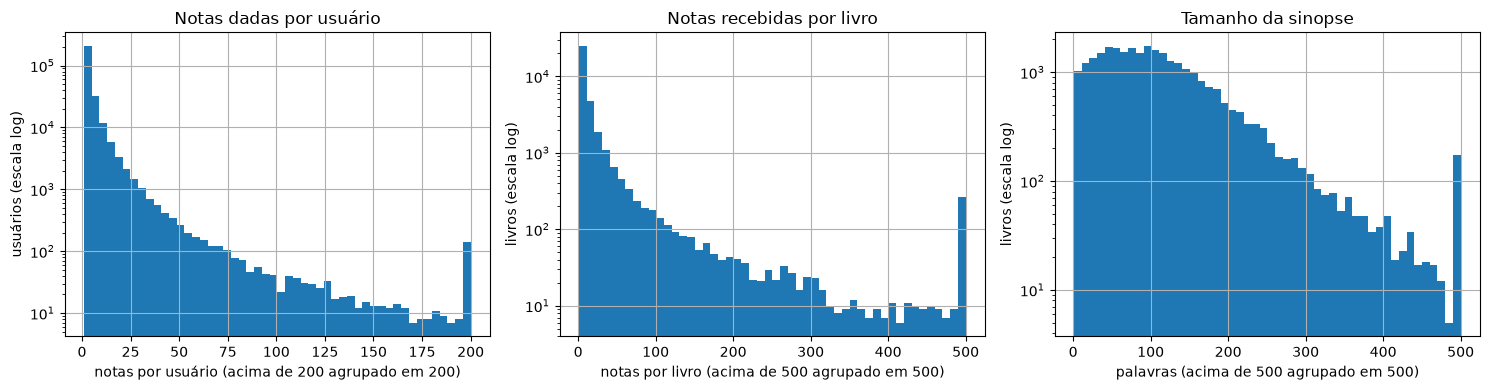

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

per_user.clip(upper=200).hist(bins=50, ax=ax[0])
ax[0].set_title("Notas dadas por usuário")
ax[0].set_xlabel("notas por usuário (acima de 200 agrupado em 200)")
ax[0].set_ylabel("usuários (escala log)")

per_book.clip(upper=500).hist(bins=50, ax=ax[1])
ax[1].set_title("Notas recebidas por livro")
ax[1].set_xlabel("notas por livro (acima de 500 agrupado em 500)")
ax[1].set_ylabel("livros (escala log)")

words_with_desc.clip(upper=500).hist(bins=50, ax=ax[2])
ax[2].set_title("Tamanho da sinopse")
ax[2].set_xlabel("palavras (acima de 500 agrupado em 500)")
ax[2].set_ylabel("livros (escala log)")

for a in ax:
    a.set_yscale("log")
plt.tight_layout()

### Goodreads Reviews

In [9]:
df_reviews = pd.read_json(REVIEWS_PATH, lines=True)

print(df_reviews.columns.tolist())

['user_id', 'book_id', 'review_id', 'rating', 'review_text', 'date_added', 'date_updated', 'read_at', 'started_at', 'n_votes', 'n_comments']


In [10]:
df_reviews_books = df_reviews.merge(df_books[["book_id", "title"]], on="book_id")

df_reviews_books[["title", "rating", "review_text", "n_votes"]].head()

,title,rating,review_text,n_votes
0,Old Possum's Book of Practical Cats,5,I have three younger siblings and we grew up w...,0
1,Fear of Dreaming: The Selected Poems,5,This is my favorite collection of poetry.,0
2,Bash,4,"He's so disturbing. So very, very disturbing.",0
3,Inherit the Wind,5,I just reread this play for a class I am takin...,1
4,Play the Piano Drunk Like a Percussion Instrum...,5,"Cuanto mas leo, mas me gusta. Su poesia es env...",0
